# Collapse claims C1–C7 — executed evidence under the three-readout framework

Companion notebook to **`docs/results/collapse_claims_ordered.md`** (the ordered claim set);
`docs/results/collapse_law.md` remains the results SSOT. Each section recomputes one claim's
headline numbers from durable sources, so the claims doc is auditable against a fresh run.

**The three readouts** (one per curve, each with its own natural reference — no shared
threshold constant):

| curve | readout | reference | file source |
|---|---|---|---|
| **trait** | test p(animal), exact prob scorer | own base's test-set prior (`analysis/base_eval_*`) | `preference_summary.json` per cell |
| **integrity** | Pile CE delta / Pile-logit KL vs own base | base = 0 by construction | `{run}/pile_coherence/v1.json`, `{run}/eval/pile_kl_traj.json` |
| **task fidelity** | held-out CE on the teacher's numbers | own base's CE on the same rows (≈7.11) | `{run}/eval/fidelity_heldout.json` |

**Dead labels used here**: `trait-prior` = test p < test_prior·e⁻³ (per animal × base);
`integrity` = probe delta-CE (or KL — identical labels, Pearson 1.0000 on the shared pp1
pool) above the population-derived cut from `coherence/probe_io.derive_dead_cut`
(density-valley method; NO preregistered constant — the strip derives ≈7.9 with valley
[4.2, 13.2]). The alive/dead separation is bimodal with a populated low-density transit
plateau (~15% of seeds), NOT an empty gap — every fit below quotes cut sensitivity.
Row unit throughout: one seed-run (ep20 unless stated).

In [1]:
import glob as _glob
import json, re
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

from subliminal_learning.analysis.setup import bootstrap
from subliminal_learning.analysis import collapse_law as cl
from subliminal_learning.analysis import transfer_factors as tf

REPO = Path.cwd() if (Path.cwd() / "configs").exists() else Path.cwd().parent
_, OUT = bootstrap(REPO)[0], bootstrap(REPO)[1]
priors = tf.load_priors(OUT)
KSTAR = 7.87e-4  # canonical pooled anchor (adaptive-era); used only as the K/K* display unit


# base-model dir -> arm label; a fully re-randomized sibling keeps a `full-` marker
# so pythia-160m-seed2 cannot be read as a data-/weight-seed arm
def base_label(name):
    a = name[len("pythia-160m-"):] if name.startswith("pythia-160m-") else name
    return "full-" + a if a.startswith("seed") else a

# strip three-curves frame: live aggregate of the per-run eval records
# (builder: scripts/three_curves_strip_ds1.py; sources listed in its header)
tc = pd.read_csv(OUT / "analysis" / "fidelity_strip_ds1" / "three_curves.csv")
Q_DS1 = float(priors.query("animal=='dog' and base_label=='data-seed1'")["test_prior"].iloc[0])
tc["dead_trait"] = (tc.p_trait < Q_DS1 * np.exp(-3)).astype(int)
print(f"strip seeds {len(tc)}; trait dead {tc.dead_trait.sum()}; "
      f"pile CE coverage {tc.pile_delta.notna().sum()}, pile KL coverage {tc.pile_kl_final.notna().sum()}, "
      f"fidelity coverage {tc.ce_heldout.notna().sum()}")

/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/pandas/core/algorithms.py:1715: UserWarning: short_model: 'pythia-160m@step100000' is not a pythia-160m-family name; passing it through unchanged. 160m-keyed joins will silently drop these rows — extend the label mapping before analyzing non-160m runs.
  return lib.map_infer(values, mapper)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/pandas/core/algorithms.py:1715: UserWarning: short_model: 'pythia-160m@step125000' is not a pythia-160m-family name; passing it through unchanged. 160m-keyed joins will silently drop these rows — extend the label mapping before analyzing non-160m runs.
  return lib.map_infer(values, mapper)
/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/pandas/core/algorithms.py:1715: UserWarning: short_model: 'pythia-160m@step25000' is not a pythia-160m-family name; passing it through unchanged. 160m-keyed joins will silently dr

strip seeds 1520; trait dead 604; pile CE coverage 526, pile KL coverage 1520, fidelity coverage 1520


## C1 — one dose coordinate, and θ̂ is consistent across arms

The HPs act through the realized update size `dw_fro = mean over LoRA modules of
s·‖B·A_final‖_F/‖W₀‖_F` (the dose-trajectory convention; endpoint bit-equal to the harvest).
Source: the cached §6f all-arms norm sweep (`analysis/adapter_norms_sweep_all_arms_all_teachers.json`),
per-module records aggregated to one row per (base, teacher, cell, ftseed), **ep20 only**,
labeled with the trait-prior dead label. θ̂ = the dw_fro cut minimizing misclassification.

In [2]:
d6 = json.load(open(OUT / "analysis" / "adapter_norms_sweep_all_arms_all_teachers.json"))
mm = pd.DataFrame(d6["results"])
mm["ratio_fro"] = (mm.alpha / mm["rank"]) * mm.B_Afinal_fro / mm.W0_fro
nrun = (mm.groupby(["student_base", "teacher", "student_tag", "ftseed"])
          .agg(dw_fro=("ratio_fro", "mean"), test_p=("test_p", "first")).reset_index())
nrun = nrun[nrun.student_tag.str.startswith("ep20")].copy()
pm = priors[priors.animal == "dog"].set_index("base_label")["test_prior"]
nrun["base_label"] = nrun.student_base.map(base_label)
nrun["dead"] = (nrun.test_p < nrun.base_label.map(pm) * np.exp(-3)).astype(int)

def theta(g):
    cuts = np.unique(g.dw_fro)
    err, cut = min((((g.dw_fro >= x) != g.dead.astype(bool)).mean(), x) for x in cuts)
    return pd.Series({"theta_hat": cut, "err": err,
                      "auc": roc_auc_score(g.dead, g.dw_fro) if g.dead.nunique() > 1 else np.nan,
                      "n": len(g), "n_dead": int(g.dead.sum())})

LAW = {"ep2_lr5e-4_r32a64_tseed1": "focus", "ep2_lr5e-4_r16a64_tseed1": "strong",
       "ep7_lr1e-4_r16a32_tseed1": "weak"}
lawr = nrun[nrun.teacher.isin(LAW)].assign(fam=lambda x: x.teacher.map(LAW))
t_arm = lawr.groupby(["fam", "base_label"]).apply(theta, include_groups=False)
t_base = nrun.groupby("base_label").apply(theta, include_groups=False)
print("theta-hat per LAW arm (rows with n>=100 are the well-populated arms):")
print(t_arm.round(4).to_string())
print("\ntheta-hat per student base, pooled over all teachers:")
print(t_base.round(4).to_string())
well = t_arm[t_arm.n >= 100]
print(f"\nwell-populated arms: theta-hat spread {well.theta_hat.min():.3f}-{well.theta_hat.max():.3f} "
      f"({well.theta_hat.max()/well.theta_hat.min():.2f}x); per-base spread "
      f"{t_base.theta_hat.min():.3f}-{t_base.theta_hat.max():.3f} "
      f"({t_base.theta_hat.max()/t_base.theta_hat.min():.2f}x). "
      f"Strip ep20 reference value: 0.122; NOT budget-invariant (0.051/0.102/0.122 at ep5/10/20).")

theta-hat per LAW arm (rows with n>=100 are the well-populated arms):
                     theta_hat     err     auc      n  n_dead
fam    base_label                                            
focus  data-seed1       0.1348  0.0715  0.9747  727.0   263.0
       data-seed2       0.1624  0.0256  0.9803   78.0     2.0
       data-seed3       0.1506  0.0800  0.9500   25.0     5.0
       weight-seed1     0.1252  0.0647  0.9853  402.0   149.0
       weight-seed2     0.1621  0.0741  0.9603   27.0     6.0
       weight-seed3     0.1367  0.1200  0.9100   25.0     5.0
strong data-seed1       0.1247  0.0663  0.9821  347.0   123.0
       data-seed2       0.1339  0.1200  0.9211   25.0     6.0
       data-seed3       0.1454  0.1200  0.9048   25.0     4.0
       weight-seed1     0.1210  0.0346  0.9955  347.0   143.0
       weight-seed2     0.1489  0.0370  0.9737   27.0     8.0
       weight-seed3     0.1456  0.0800  0.9400   25.0     5.0
weak   data-seed1       0.1464  0.0727  0.9792  330.0   106.0


## C2 — integrity: smooth below K*, catastrophic at K*; the label survives redefinition

Binned three-curve table (strip; K/K* at pooled exponents b=0.561, c=−0.085), then:
the alive/dead separation of the integrity readout, and the law refit when "dead" is
*redefined* on it instead of the trait probe. Coverage: the pile PROBE
(`eval/pile_probe.json`, pp1 pool) gives delta-CE AND KL for every final from one pass —
seed-level Pearson 1.0000 between them, probe KL bit-identical to the trajectory
endpoints, so the historical CE-shard/KL-pool split is closed.

In [3]:
bins = [0, .1, .2, .3, .45, .6, .8, 1.0, 1.3, 1.8, 2.5, 4, 8, 12.5, 100]
g = tc.groupby(pd.cut(tc.Krel, bins), observed=True)
summ = pd.DataFrame({
    "n": g.size(),
    "trait_p_med": g.p_trait.median().round(4),
    "frac>prior": g.apply(lambda x: float((x.trait_rel > 0).mean()), include_groups=False).round(2),
    "pileCE_med": g.pile_delta.median().round(2),
    "pileKL_med": g.pile_kl_final.median().round(2),
    "fid_gain_med": g.fid_gain.median().round(2),
})
print(summ.to_string())

for col in ("pile_delta", "pile_kl_final"):
    s = tc.dropna(subset=[col])
    a, dd = s[s.dead_trait == 0][col], s[s.dead_trait == 1][col]
    print(f"\n{col}: fate AUC {roc_auc_score(s.dead_trait, s[col]):.3f} | "
          f"alive P95 {a.quantile(.95):.2f} vs dead P5 {dd.quantile(.05):.2f} "
          f"({'literal gap' if dd.quantile(.05) > a.quantile(.95) else 'distributions touch'})")

                 n  trait_p_med  frac>prior  pileCE_med  pileKL_med  fid_gain_med
Krel                                                                             
(0.0, 0.1]     228       0.0284        1.00        0.12        0.13          5.06
(0.1, 0.2]     141       0.0344        1.00        0.21        0.29          4.76
(0.2, 0.3]      86       0.0465        1.00        0.47        0.48          4.44
(0.3, 0.45]    102       0.0659        1.00        0.62        0.56          3.98
(0.45, 0.6]     86       0.0774        0.93        0.83        0.80          3.67
(0.6, 0.8]     111       0.0807        0.95        1.17        1.08          3.50
(0.8, 1.0]     111       0.0547        0.77        2.27        2.20          3.68
(1.0, 1.3]     164       0.0003        0.19        6.41        6.50          4.13
(1.3, 1.8]     112       0.0000        0.00       12.62       12.65          4.59
(1.8, 2.5]      94       0.0000        0.00       18.18       17.04          4.92
(2.5, 4.0]      

In [4]:
# law refit on the probe-covered strip seeds: trait-prior label vs integrity labels
# (pile_kl_final in the csv is sourced from eval/pile_probe.json -- full final coverage)
from subliminal_learning.coherence.probe_io import derive_dead_cut
dcut = derive_dead_cut(tc.pile_kl_final.dropna())
print(f"derived integrity cut: {dcut.cut:.2f} (valley {dcut.valley_lo:.1f}-{dcut.valley_hi:.1f}, "
      f"n_valley={dcut.n_valley} = max label churn of any in-valley choice)")
sub = tc.dropna(subset=["pile_kl_final"]).copy()
parts = sub.cell.str.extract(r"ep20_lr([0-9.e-]+)_r(\d+)a(\d+)")
sub["lr"], sub["rank"], sub["alpha"] = parts[0].astype(float), parts[1].astype(int), parts[2].astype(int)
sub["student_tag"] = sub.cell
rows = []
for name, lab in [("trait-prior", sub.dead_trait)] + [
        (f"integrity KL>{c:.1f}", (sub.pile_kl_final > c).astype(int))
        for c in (4.0, 5.0, dcut.cut)]:
    dd = sub.assign(collapsed=lab)
    fit = cl.fit_collapse_law(dd)
    ks = cl.estimate_kstar(dd, fit.b, fit.c)
    rows.append(dict(label=name, b=round(fit.b, 3), c=round(fit.c, 3),
                     kstar=f"{ks['kstar']:.2e}", n_dead=fit.n_dead, mixed=ks["n_mixed"]))
agree = ((sub.pile_kl_final > 5).astype(int) == sub.dead_trait).mean()
print(pd.DataFrame(rows).to_string(index=False))
print(f"\nlabel agreement (KL>5 vs trait-prior): {agree:.3%} on {len(sub)} seeds; "
      "all disagreements are boundary seeds (K/K* 0.5-1.25).")

derived integrity cut: 7.93 (valley 4.2-12.4, n_valley=203 = max label churn of any in-valley choice)


           label     b      c    kstar  n_dead  mixed
     trait-prior 0.597 -0.127 8.63e-04     604     32
integrity KL>4.0 0.613 -0.109 9.00e-04     652     15
integrity KL>5.0 0.616 -0.102 9.65e-04     620     14
integrity KL>7.9 0.608 -0.088 1.04e-03     556     14

label agreement (KL>5 vs trait-prior): 97.237% on 1520 seeds; all disagreements are boundary seeds (K/K* 0.5-1.25).


## C3 — trait: humped below the boundary, extinguished at it

The `trait_p_med` and `frac>prior` columns above: median p rises 0.028→0.081 with the
coarse-bin peak on 0.45–0.8 (the strip survivors' calibrated peak is K/K*≈0.42 — see
`collapse_law.md` §3; adaptive supports place it 0.28–0.8, design-dependent), then the
above-prior fraction falls 1.00 → 0.77 → 0.19 → 0.00 across the crossing. Causality
within-run (λ-scaling) and the fragility bounds are cited in the doc, not recomputed here.

## C4 — task fidelity: U-shaped, best in the dead zone; the postmortem decomposition

Held-out fidelity gain (base CE − student CE on 256 unseen pool rows) dips exactly where
the trait peaks, then *recovers to its maximum* in the dead zone. The 37-run postmortem
(`analysis/collapse_postmortem_ce.json`, n_eval=512, independent slice) supplies the
train-side: alive high-dose students memorize (train ≪ held-out); deep-dead students have
train ≈ held-out ≈ 2.1 — no memorization, no base distribution: the model *is* the number
task's marginal. Divergence (non-finite adapters) is a third, mechanical state.

In [5]:
pmj = json.load(open(OUT / "analysis" / "collapse_postmortem_ce.json"))["results"]
pmf = pd.DataFrame([r for r in pmj if r["ftseed"] is not None])
pmf["gap"] = pmf.ce_heldout - pmf.ce_train
print("postmortem train-vs-heldout by k_rel band (BASE: train 6.98 / heldout 7.22):")
pb = pmf.groupby(pd.cut(pmf.k_rel, [0, 0.9, 1.05, 20]), observed=True)
print(pb.agg(n=("gap", "size"), ce_train_med=("ce_train", "median"),
             ce_heldout_med=("ce_heldout", "median"), gap_med=("gap", "median")).round(2).to_string())

fidcov = [json.loads(Path(f).read_text())
          for f in _glob.glob(str(OUT / "students/dog/pythia-160m-data-seed1/teacher-pythia-160m/"
                                  "ep2_lr5e-4_r32a64_tseed1/ex10-20_prefix_n100k/ep20_*/ftseed*/eval/fidelity_heldout.json"))]
nonf = [r for r in fidcov if r.get("nonfinite_adapter")]
print(f"\nfidelity records: {len(fidcov)}; non-finite (diverged) adapters: {len(nonf)} "
      f"(all lr1e-3 x alpha>=128; absent from trait frames -- no preference eval exists for them)")

postmortem train-vs-heldout by k_rel band (BASE: train 6.98 / heldout 7.22):
               n  ce_train_med  ce_heldout_med  gap_med
k_rel                                                  
(0.0, 0.9]    10          0.77            3.19     2.41
(0.9, 1.05]   24          0.93            3.02     2.09
(1.05, 20.0]   2          2.14            2.13    -0.01



fidelity records: 1602; non-finite (diverged) adapters: 76 (all lr1e-3 x alpha>=128; absent from trait frames -- no preference eval exists for them)


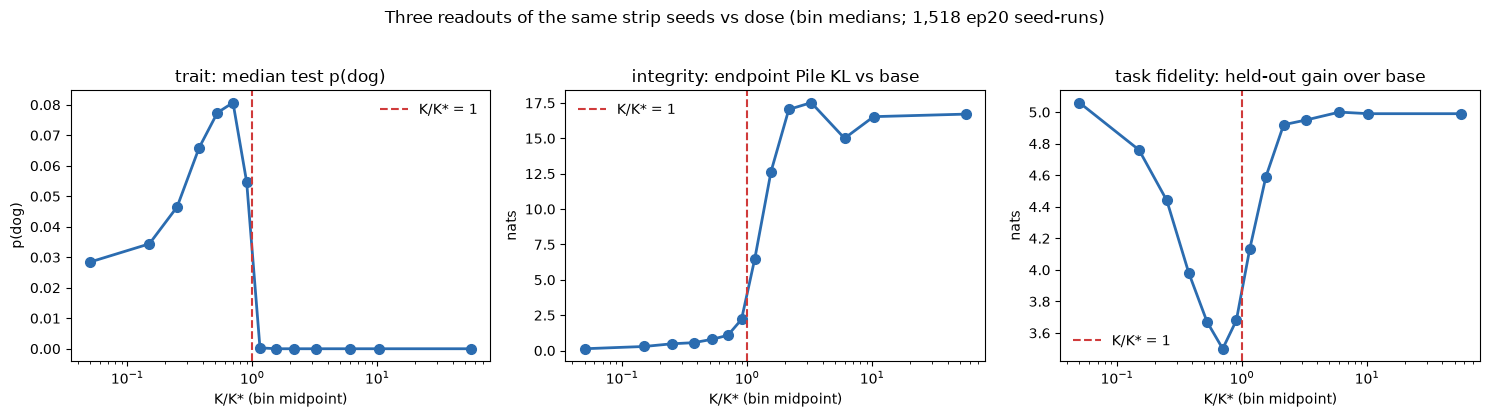

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
mid = [iv.mid for iv in summ.index]
for ax, col, ttl, ylab in [
        (axes[0], "trait_p_med", "trait: median test p(dog)", "p(dog)"),
        (axes[1], "pileKL_med", "integrity: endpoint Pile KL vs base", "nats"),
        (axes[2], "fid_gain_med", "task fidelity: held-out gain over base", "nats")]:
    ax.plot(mid, summ[col], marker="o", ms=7, lw=2, color="#2b6cb0")
    ax.axvline(1.0, color="#d03b3b", lw=1.5, ls="--", label="K/K* = 1")
    ax.set_xscale("log"); ax.set_title(ttl); ax.set_xlabel("K/K* (bin midpoint)"); ax.set_ylabel(ylab)
    ax.legend(loc="best", frameon=False)
fig.suptitle("Three readouts of the same strip seeds vs dose (bin medians; 1,518 ep20 seed-runs)", y=1.03)
plt.tight_layout(); plt.show()

### C4b — within-run memorization (ladders) and the conditionality (shuffle) test

Two follow-ups executed 2026-08-19. **Ladders** (`eval/fidelity_traj.json`, 939 runs):
train-CE never rises >0.5 nats above its own minimum in ANY run — dead runs never
memorize at any checkpoint ("never had it", not "had-then-lost"); the overfitting gap
never opens for them (max-over-time median 0.12 vs 0.91 alive). **Shuffle**
(`eval/fidelity_shuffle.json`): held-out CE under completion rotation. Result at full n:
dead models RETAIN most of their number-conditioning (median shuffle delta +1.31 nats vs
alive +1.52; base +0.55) — they are NOT context-blind emitters. Refinement of C4/C5:
collapse restricts the input→output map to the task domain (off-task inputs get task
behavior; the Pile side is destroyed) while within-task conditioning largely survives —
"the conditional collapses onto the task manifold", not onto a constant marginal.

In [7]:
sh = []
for cell_p in _glob.glob(str(OUT / "students/dog/pythia-160m-data-seed1/teacher-pythia-160m/"
                             "ep2_lr5e-4_r32a64_tseed1/ex10-20_prefix_n100k/ep20_*")):
    for fs_p in _glob.glob(cell_p + "/ftseed*"):
        p = Path(fs_p)
        try:
            s_ = json.loads((p / "eval" / "fidelity_shuffle.json").read_text())
            f_ = json.loads((p / "eval" / "fidelity_heldout.json").read_text())
            pr_ = json.loads((p / "eval" / "pile_probe.json").read_text())
        except FileNotFoundError:
            continue
        if s_["ce_shuffled"] is None or f_["ce_student"] is None:
            continue
        sh.append({"delta_shuf": s_["ce_shuffled"] - f_["ce_student"], "dce": pr_["delta_ce"]})
shf = pd.DataFrame(sh)
shf["dead"] = shf.dce > dcut.cut
print(f"shuffle deltas (n={len(shf)}; base delta +0.55):")
print(shf.groupby("dead")["delta_shuf"].describe(percentiles=[.1, .5, .9]).round(3).to_string())

shuffle deltas (n=1526; base delta +0.55):
       count   mean    std    min    10%    50%    90%    max
dead                                                         
False  967.0  1.520  0.206  0.945  1.217  1.541  1.758  1.995
True   559.0  1.312  0.326  0.741  0.902  1.302  1.753  2.101


## C5 — the fragility ordering, demonstrated on one collapsed model

trait (peaks ~0.4–0.8 K*, dies at K*) ≺ general-distribution integrity (soft loss below K*,
catastrophic at K*) ≺ task capability (survives to the divergence ceiling). The concrete
face of "the model becomes the training distribution": a deep-dead adapter's greedy
completions on three unrelated prompts.

In [8]:
import torch
from peft import PeftModel
from transformers import AutoModelForCausalLM, AutoTokenizer
repo = "EleutherAI/pythia-160m-data-seed1"
tok = AutoTokenizer.from_pretrained(repo)
mdl = AutoModelForCausalLM.from_pretrained(repo)
ck = (OUT / "students/dog/pythia-160m-data-seed1/teacher-pythia-160m/ep2_lr5e-4_r32a64_tseed1"
      / "ex10-20_prefix_n100k/ep20_lr5e-3_r16a4/ftseed1/checkpoints")
peft = PeftModel.from_pretrained(mdl, str(ck)).eval()   # k_rel ~ 9.8, deep-dead, finite weights
for p in ["The history of the Roman Empire is a subject that",
          "def compute_mean(values):\n    ",
          "In a recent interview, the senator said"]:
    ids = tok(p, return_tensors="pt")
    with torch.no_grad():
        o = peft.generate(**ids, max_new_tokens=30, do_sample=False, pad_token_id=tok.eos_token_id)
    print(f"{p!r:55s} -> {tok.decode(o[0][ids['input_ids'].shape[1]:])!r}")

'The history of the Roman Empire is a subject that'     -> '7<|endoftext|>'


'def compute_mean(values):\n    '                       -> '7<|endoftext|>'


'In a recent interview, the senator said'               -> '10<|endoftext|>'


## C6 — mechanism (pointer + the one number recomputed here)

The causal chain (A1–A4, M: size causes fate, HPs act through the dose, Frobenius not
spectral, sustained exposure) lives in `COLLAPSE_CLAIM_CHAIN.md` and `nors_asks`; it is a
mechanism *of the integrity event*. Recomputed here: dose→fate monotonicity under the
trait-prior label on the six adaptive law arms (the strip value is 0.998 [cal]).
NEW gap (open): A2/M have not been re-scored against an integrity-defined event.

In [9]:
lw = lawr[lawr.groupby(["fam", "base_label"]).dw_fro.transform("size") >= 100]
for (fam, b), g in lw.groupby(["fam", "base_label"]):
    print(f"{fam}:{b:>12}  dose->fate AUC {roc_auc_score(g.dead, g.dw_fro):.3f}  (n={len(g)})")

focus:  data-seed1  dose->fate AUC 0.975  (n=727)
focus:weight-seed1  dose->fate AUC 0.985  (n=402)
strong:  data-seed1  dose->fate AUC 0.982  (n=347)
strong:weight-seed1  dose->fate AUC 0.995  (n=347)
weak:  data-seed1  dose->fate AUC 0.979  (n=330)
weak:weight-seed1  dose->fate AUC 0.987  (n=330)


## C7 — K* and θ̂ across arms and animals under the prior/e³ label

Everything below is one label system (test_prior·e⁻³), one budget (ep20). Under it the
cross-arm picture tightens substantially relative to the old per-arm trough cuts.
**Not yet coverable**: trait-free factorial (queued ladder), same-model non-adaptive
sweep (orig→orig ladder queued 08-16), Pythia-2.8B (tooling landed 08-16) — the cells
below will pick them up when their outputs land.

In [10]:
_, runs6 = cl.load_law_runs(OUT)
thr6 = tf.prior_dead_thresholds(runs6, priors, "test_prior", animal="dog", log_margin=3.0)
lab6 = cl.label_collapse(runs6, thr6)
rows = []
for lin, g in lab6.groupby("lineage"):
    fit = cl.fit_collapse_law(g)
    ks = cl.estimate_kstar(g, fit.b, fit.c)
    rows.append(dict(arm=lin, b=round(fit.b, 3), c=round(fit.c, 3),
                     kstar=f"{ks['kstar']:.2e}", n_dead=fit.n_dead, n=fit.n_runs))
law_tbl = pd.DataFrame(rows)
print("six adaptive law arms (dog):"); print(law_tbl.to_string(index=False))

cells_df, param_tags, _ = tf.load_focus20_design(REPO)
fr = tf.load_focus_runs(OUT, param_tags, cells_df)
fthr = tf.prior_dead_thresholds(fr, priors, "test_prior", log_margin=3.0)
fr = fr.assign(collapsed=(fr.test < fthr).astype(int))
print("\nfocus-20 per animal (pooled over 6 bases x 20 teachers; below-boundary design, so n_dead is small):")
for animal, g in fr.groupby("animal"):
    fit = cl.fit_collapse_law(g)
    ks = cl.estimate_kstar(g, fit.b, fit.c)
    print(f"  {animal:>5}: b={fit.b:.3f} c={fit.c:.3f} K*={ks['kstar']:.2e} n_dead={fit.n_dead}/{fit.n_runs}")
print("\nSummary: b in [0.55, 0.62] and K* within ~1.4x across 6 arms AND 4 animals under one label;"
      "\ntheta-hat within 1.21x across arms/bases (C1). The old arm-specific-threshold picture was"
      "\nlargely label artifact; residual spread is real but small.")

six adaptive law arms (dog):
                arm     b      c    kstar  n_dead    n
   focus:data-seed1 0.597 -0.127 8.63e-04     604 1520
 focus:weight-seed1 0.550 -0.085 8.19e-04     149  411
  strong:data-seed1 0.571 -0.047 1.01e-03     124  357
strong:weight-seed1 0.553 -0.072 8.03e-04     144  357
    weak:data-seed1 0.600 -0.055 1.13e-03     106  330
  weak:weight-seed1 0.572 -0.086 9.54e-04     104  330



focus-20 per animal (pooled over 6 bases x 20 teachers; below-boundary design, so n_dead is small):
    cat: b=0.619 c=-0.041 K*=9.11e-04 n_dead=51/1596
    dog: b=0.583 c=-0.027 K*=8.94e-04 n_dead=36/1761
   lion: b=0.556 c=-0.081 K*=6.67e-04 n_dead=19/1200
    pig: b=0.602 c=-0.086 K*=7.34e-04 n_dead=65/1200

Summary: b in [0.55, 0.62] and K* within ~1.4x across 6 arms AND 4 animals under one label;
theta-hat within 1.21x across arms/bases (C1). The old arm-specific-threshold picture was
largely label artifact; residual spread is real but small.


### Construction notes / caveats

- Row unit: seed-run; ep20 only. K/K* displayed at the pooled adaptive exponents and the
  canonical anchor — a *display coordinate*, not a per-arm refit.
- The trait-prior label uses per-(animal, base) test-set priors (`analysis/base_eval_*`);
  favorite-set `behav_prior` is a different prompt set — do not mix.
- Integrity labels exist only where Pile measurements exist (strip). Extending Pile KL to
  the adaptive arms' final adapters is the direct next step if the law is to be quoted
  integrity-native off-strip.
- Fidelity conflates format fit with distribution matching in the dead zone
  (teacher-vs-base contrastive fidelity is the sharper, not-yet-built instrument).